In [2]:
import pandas as pd
import numpy as np
import torch 
import matplotlib.pyplot as plt

# Fit a Bayesian GPLVM to the data with missing values

import sys
import os
from pathlib import Path

sys.path.append(str(Path(os.getcwd()).parent))  # or use relative path
print(sys.path)

from ssvi_scripts_experiments.mnist_ood_GPLVM_SSVI_AM_INF import OilFlow_SSVI_GPLVM, OODSSVIConfig, train_oil_flow_ssvi


['/Users/rsedgwick/conditional_overlaping_gaussian_processes/generalised_gplvm_code', '/Users/rsedgwick/conditional_overlaping_gaussian_processes', '/Users/rsedgwick/conditional_overlaping_gaussian_processes/gplvm_missing_data', '/Users/rsedgwick/conditional_overlaping_gaussian_processes/generalised_gplvm_code', '/Users/rsedgwick/conditional_overlaping_gaussian_processes', '/opt/anaconda3/envs/ssvi-gplvm/lib/python310.zip', '/opt/anaconda3/envs/ssvi-gplvm/lib/python3.10', '/opt/anaconda3/envs/ssvi-gplvm/lib/python3.10/lib-dynload', '', '/opt/anaconda3/envs/ssvi-gplvm/lib/python3.10/site-packages', '/Users/rsedgwick/conditional_overlaping_gaussian_processes', '/var/folders/kx/7zm2zp_54d14zbwnnl84lxlc0000gp/T/tmpzw2rybhp', '/Users/rsedgwick/conditional_overlaping_gaussian_processes']


# SSVI GPLVM for missing data in developability assays 

Data from this paper: https://www.pnas.org/doi/10.1073/pnas.2026658118

10 versions of 3 assays to do with how well a protein can be produced (6 of assay 1, 2 of assay 2, and 2 of assay 3)

can also include IQ and SH which are the high fidelity, more expensive bacterial assays but have some missing data


In [3]:
np.random.seed(2026)

In [4]:


def get_fast_config():
    """Fast configuration for testing with OOD detection enabled.

    Default: Cross-dataset OOD with FashionMNIST as ID, MNIST as OOD.
    """
    return OODSSVIConfig(
        training_iterations=1000,
        batch_size=50,
        n_inducing_points=100,
        encoder_hidden_dims=[128, 64],
        local_lr=2e-3,
        global_lr=1e-2,
        P=16,
        log_frequency=50,
        checkpoint_frequency=50,
        enable_gradient_logging=True,
        gradient_log_frequency=25,
        enable_metrics=True,
        metrics_frequency=50,
        save_training_plots=True,
        plot_training=True,
        plot_latent_space=True,
        plot_hyperparams=True,
        # === GP Hyperparameters ===
        init_lengthscales=1.0,
        init_output_noise_scale=1.0,
        # === Missing Data Configuration ===
        enable_missing_data=True,
        missing_data_ratio=0.3,
        reconstruction_samples=50,
        # === Random Seed Configuration ===
        random_seed=7,
        # === Test Size Configuration ===
        test_size=0.2,
        # === OOD Configuration (Cross-dataset mode) ===
        # FashionMNIST classes: 0=T-shirt, 1=Trouser, 2=Pullover, 3=Dress, 4=Coat,
        #                       5=Sandal, 6=Shirt, 7=Sneaker, 8=Bag, 9=Ankle boot
        # MNIST classes: 0-9 = Digits 0-9
        id_dataset="FashionMNIST",
        id_classes=[1, 2],  # Trouser, Pullover
        id_samples_per_class=100,
        ood_dataset="MNIST",  # Explicitly specify OOD dataset
        ood_classes=[1, 2],  # Digits 1, 2
        ood_samples_per_class=100,
        # === OOD Evaluation Configuration ===
        ood_n_samples=16,  # Number of samples for OOD evaluation
    )


## Load and process data

In [5]:
# data = pd.read_excel('/Users/rsedgwick/Downloads/pnas.1616408114.sd03.xlsx')
# data = data.iloc[:137]
# get all columns except 'Name'
# data_np = data.drop(columns=['Name']).to_numpy()

data = pd.read_csv('assay_to_yield_training_sequences.csv')
# data_np = data.drop(columns=['Unnamed: 0', '#OTU ID', 'DNA', 'Paratope', 'Stop', 'CC', 'Position_x', 'Position_y', 'One_Hot', 'Ordinal']).to_numpy()

# get only the assay score columns as numpy array
data_np = data[['Sort1_mean_score', 
       'Sort2_mean_score',
       'Sort3_mean_score',
       'Sort4_mean_score',
       'Sort5_mean_score', 
       'Sort6_mean_score',
       'Sort7_mean_score', 
       'Sort8_mean_score',
       'Sort9_mean_score', 
       'Sort10_mean_score',
]].to_numpy() 
#       'IQ_Average',
      # 'SH_Average'

# cast data_np to float type 
data_np = data_np.astype(float)

In [6]:
data.head()

,Unnamed: 0,#OTU ID,DNA,Paratope,Stop,CC,Sort1_1_score,Sort1_2_score,Sort1_3_score,Sort2_1_score,...,IQ_Average_bc,IQ_Trial1_Adj_bc,IQ_Trial2_Adj_bc,IQ_Trial3_Adj_bc,IQ_Average_bc_std,SH_Average_bc,SH_Trial1_Adj_bc,SH_Trial2_Adj_bc,SH_Trial3_Adj_bc,SH_Average_bc_std
0,982,Zotu1433,AAATTTTGGGCGACTGTAGGTGTGTATCGTTTGTCGAGGCATTTTG...,GVYRLSRHPKLXXALQ,False,0,0.219029,0.488903,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,-0.041369,-0.137243,0.460557,-1.012433,0.740836
1,1008,Zotu1480,AAATTTTGGGCGACTGTATGTCCGAGTCATCATGGTCGTTGTTTTG...,CPSHHGRCLRFRREHG,False,1,0.491984,0.842559,0.921503,0.614348,...,NaN,NaN,NaN,NaN,NaN,1.250529,1.118242,1.054481,1.476938,0.227742
2,1196,Zotu1826,AAATTTTGGGCGACTGTATGTCATCTTTCGGTGTGTTTTGAGGTGC...,CHLXXSVCLVLRDVNG,False,1,0.666667,0.333333,0.887965,0.331793,...,NaN,NaN,NaN,NaN,NaN,0.641699,1.243834,-1.361552,0.320088,1.320938
3,1217,Zotu1862,AAATTTTGGGCGACTGTATGTGGTCGTGATCGTTGGTGTTTTGAGG...,CGRDXRWCHVFXXLCG,False,1,0.974636,0.974391,1.000000,0.874199,...,-0.00654,0.220159,-0.503406,0.105802,0.388964,0.668209,0.295409,1.186681,-0.183638,0.695416
4,1316,Zotu2013,AAATTTTGGGCGACTGTATGTATGGGTTCTCCGTGGTGTTTTGAGG...,CMGSXPWCVGQXXSCT,False,1,0.930717,0.993982,1.000000,0.659117,...,-0.18297,-0.550264,-0.188980,0.081603,0.317017,1.256685,1.558167,1.416891,-0.463381,1.128572


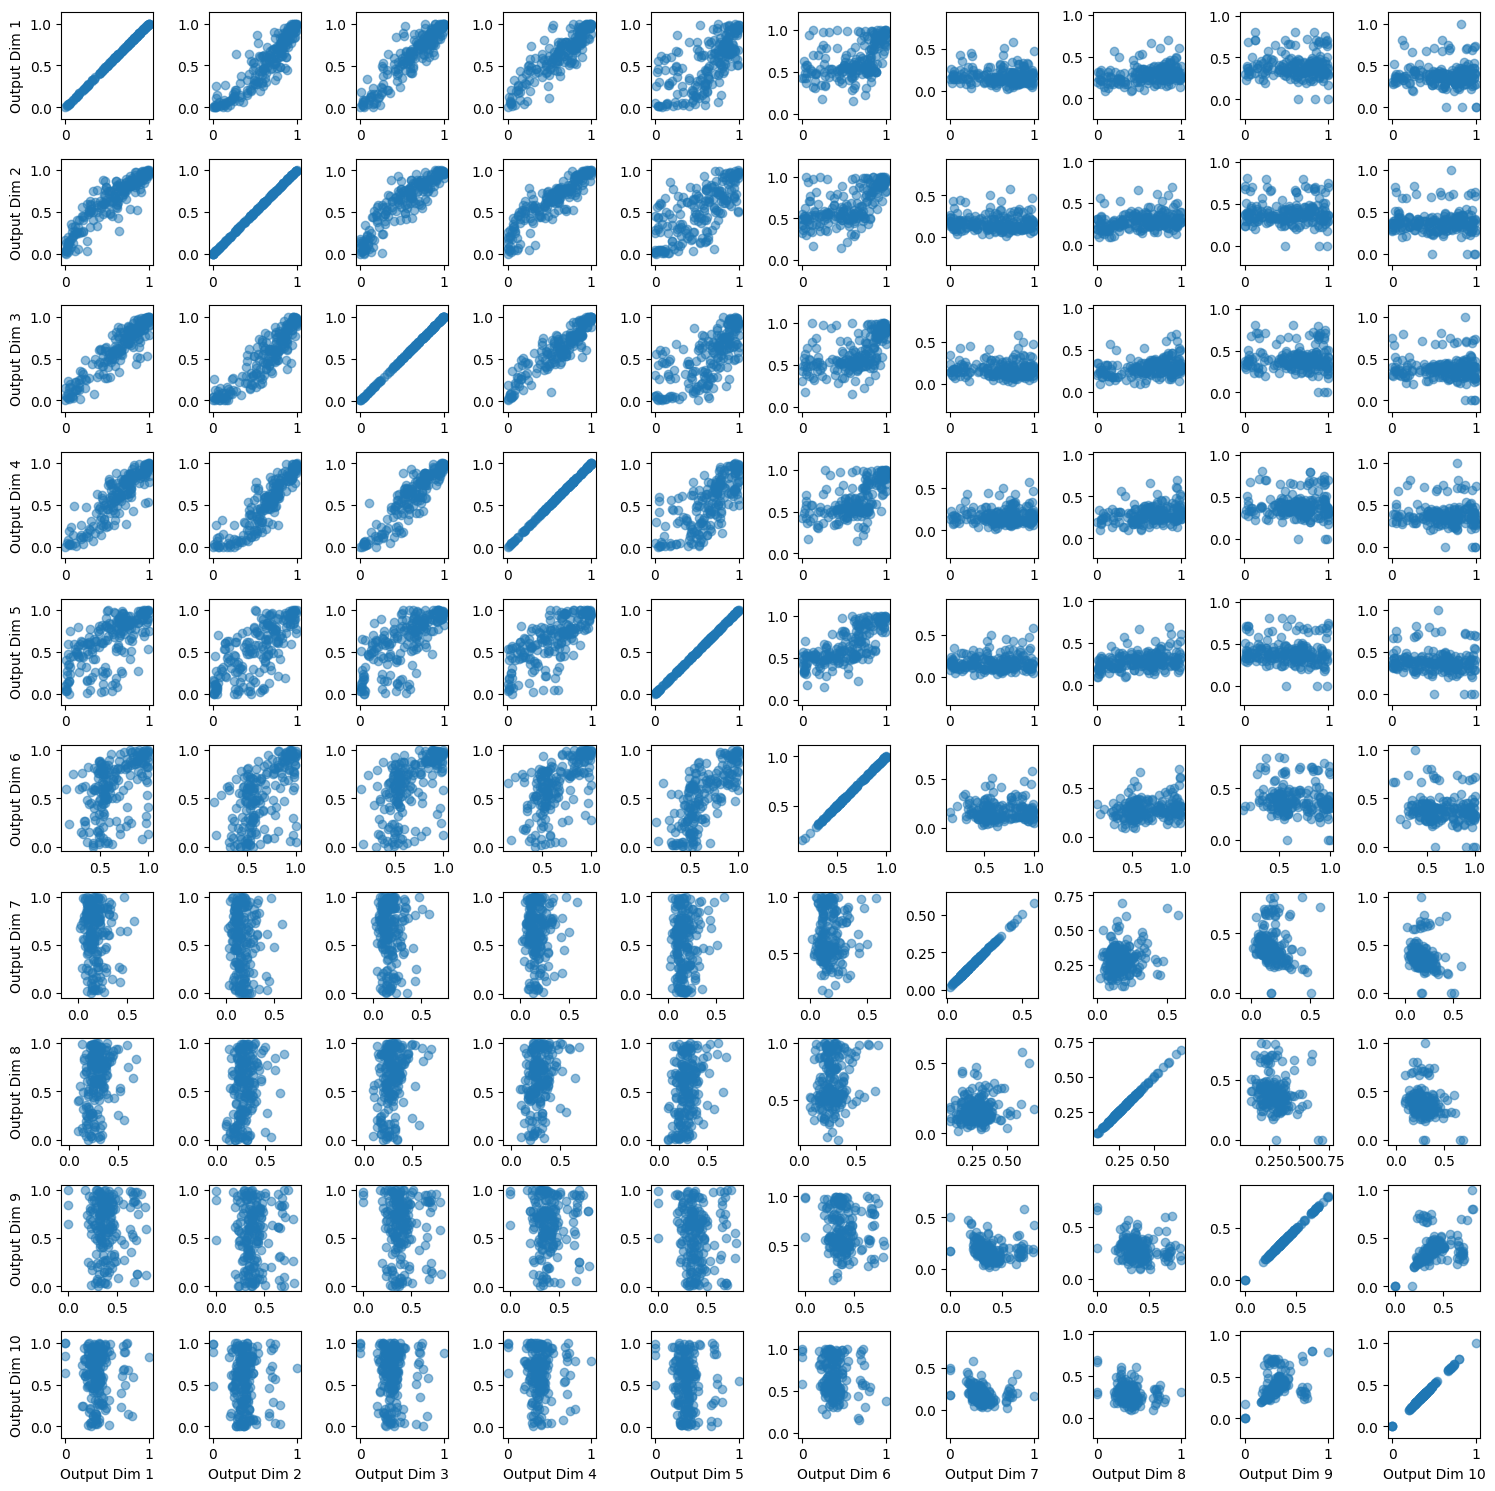

In [7]:
# plot the columns against each other in a scatter matrix

fig, axs = plt.subplots(nrows=len(data_np[0]), ncols=len(data_np[0]), figsize=(15, 15))
for i in range(len(data_np[0])):
    for j in range(len(data_np[0])):
        axs[i, j].scatter(data_np[:, i], data_np[:, j], alpha=0.5)
        axs[i, j].axis('equal')
        axs[i, 0].set_ylabel(f'Output Dim {i+1}')
        axs[-1, j].set_xlabel(f'Output Dim {j+1}')

plt.tight_layout()
plt.show()


In [8]:
# Create a mask and introduce missing values to data_np
missing_rate = 0.15  # 15% missing values

# Create a random mask (True = missing, False = observed)
missing_mask = np.random.rand(*data_np.shape) < missing_rate

# Create a copy of data_np with NaN values
data_np_with_missing = data_np.copy()
data_np_with_missing[missing_mask] = np.nan

print(f"Total values: {data_np.size}")
print(f"Missing values: {missing_mask.sum()}")
print(f"Missing percentage: {100 * missing_mask.sum() / data_np.size:.2f}%")
print(f"Data shape: {data_np_with_missing.shape}")


Total values: 1950
Missing values: 285
Missing percentage: 14.62%
Data shape: (195, 10)


## Need a different standard scaler that can deal with nans

In [9]:

class StandardScalerPytorch:
    """Standard Scaler for PyTorch tensors"""

    def __init__(self, device="cpu"):
        self.device = device

    def fit(self, X):
        """Fit the scaler to the data"""
        self.mean = torch.nanmean(X, dim=0)
        self.std = np.nanstd(X.numpy(), axis=0, ddof=0)
        self.std = torch.tensor(self.std, dtype=torch.float64, device=self.device)

    def transform(self, X):
        """Transform the data"""
        return (X - self.mean) / self.std

    def inverse_transform(self, X):
        """Inverse transform the data"""
        return X * self.std + self.mean

    def fit_transform(self, X):
        """Fit and transform the data"""
    
        self.fit(X)
        return self.transform(X)

## Fit Model

In [10]:

n_inducing_points = 20

config = get_fast_config()

Vx = torch.randn(
        n_inducing_points,
        config.latent_dim,
        dtype=torch.float64,
        device=config.device,
    )


# how to initialize mu_x using PCA for missing data?
# mu_x, _, _ = torch.pca_lowrank(y_trai, config.latent_dim)

data_with_missing = torch.tensor(data_np_with_missing, dtype=torch.float64)

mu_x = torch.nn.Parameter(torch.randn(len(data_with_missing), config.latent_dim, dtype=torch.float64) * 0.1)

scaler = StandardScalerPytorch(device=config.device)

y_train = scaler.fit(data_with_missing)
y_train = scaler.transform(data_with_missing)

all_data = torch.tensor(data_np, dtype=torch.float64)

data_np_with_missing[missing_mask] = np.nan

missing_mask = torch.isnan(data_with_missing)

data_missing_values = all_data.clone()

data_missing_values[missing_mask] = torch.nan

y_test = scaler.transform(data_missing_values)

config.total_size = y_train.shape[0]

model = OilFlow_SSVI_GPLVM(
        config=config, Vx=Vx, mu_x=mu_x, M=y_train.shape[1]  # Observation dimension
    )

Missing data reconstruction enabled


/opt/anaconda3/envs/ssvi-gplvm/lib/python3.10/site-packages/torch/_compile.py:53: UserWarning: optimizer contains a parameter group with duplicate parameters; in future, this will cause an error; see github.com/pytorch/pytorch/issues/40967 for more information
  return disable_fn(*args, **kwargs)


In [11]:
y_train

tensor([[-1.4324, -1.3201, -2.1371,  ..., -0.5166, -0.4995,  2.0878],
        [ 0.4292,  0.5526,  0.0108,  ...,  0.2393, -0.4669, -0.6437],
        [    nan,     nan, -0.5630,  ...,     nan, -0.4908, -0.3311],
        ...,
        [    nan,  0.5837,  0.7699,  ..., -1.3370,  0.0178,  0.4445],
        [ 0.8111,  0.6309,  0.8783,  ...,  1.4917, -0.2712, -0.1062],
        [    nan,     nan,  0.8667,  ...,     nan,  0.3833,  0.2350]])

In [12]:

training_result, metrics_computer = train_oil_flow_ssvi(
        model, y_train, config, logger=None, split_data=None, labels_train=None
    )


Training FashionMNIST SSVI GP-LVM...
Iterations: 1000, Batch size: 50
Iteration 0/1000
  Loss: 16.5416
  Time elapsed: 0.1s
Iteration 50/1000
  Loss: 14.1810
  Time elapsed: 1.8s
Iteration 100/1000
  Loss: 12.6441
  Time elapsed: 3.5s
Iteration 150/1000
  Loss: 13.2644
  Time elapsed: 5.2s
Iteration 200/1000
  Loss: 11.7480
  Time elapsed: 6.8s
Iteration 250/1000
  Loss: 12.4397
  Time elapsed: 8.4s
Iteration 300/1000
  Loss: 11.6372
  Time elapsed: 10.1s
Iteration 350/1000
  Loss: 12.2852
  Time elapsed: 11.7s
Iteration 400/1000
  Loss: 11.4356
  Time elapsed: 13.3s
Iteration 450/1000
  Loss: 11.7516
  Time elapsed: 15.1s
Iteration 500/1000
  Loss: 11.1341
  Time elapsed: 16.7s
Iteration 550/1000
  Loss: 11.5433
  Time elapsed: 18.3s
Iteration 600/1000
  Loss: 11.0273
  Time elapsed: 20.0s
Iteration 650/1000
  Loss: 10.6789
  Time elapsed: 21.6s
Iteration 700/1000
  Loss: 10.5814
  Time elapsed: 23.2s
Iteration 750/1000
  Loss: 11.4352
  Time elapsed: 24.8s
Iteration 800/1000
  Loss: 

In [13]:
for name, param in model.named_parameters():
    print(f"{name}: {param.size()}")

_log_sigma2: torch.Size([])
mu_x_train: torch.Size([16, 195, 6])
_log_sigma_x_train: torch.Size([16, 195, 6])
_mu_u: torch.Size([10, 20])
gp.Vx: torch.Size([20, 6])
gp._log_beta: torch.Size([1, 6])
gp._log_sigma2_s: torch.Size([1])
gp._mu_u: torch.Size([10, 20])
gp._raw_chol: torch.Size([10, 20, 20])
mu_encoder.0.weight: torch.Size([128, 210])
mu_encoder.0.bias: torch.Size([128])
mu_encoder.2.weight: torch.Size([64, 128])
mu_encoder.2.bias: torch.Size([64])
mu_encoder.4.weight: torch.Size([6, 64])
mu_encoder.4.bias: torch.Size([6])
sigma_encoder.0.weight: torch.Size([128, 210])
sigma_encoder.0.bias: torch.Size([128])
sigma_encoder.2.weight: torch.Size([64, 128])
sigma_encoder.2.bias: torch.Size([64])
sigma_encoder.4.weight: torch.Size([6, 64])
sigma_encoder.4.bias: torch.Size([6])


## Calculate Metrics

In [14]:
from src.ssvi_metrics import SSVIMetricsComputer
metrics_computer = SSVIMetricsComputer(
            device=config.device, metrics_batch_size=config.batch_size
        )

In [15]:
final_metrics = metrics_computer.compute_full_metrics(
                model=model,
                y_train=y_train,
                y_test=y_test,
                iteration=config.training_iterations,
                elbo_loss=training_result['full_elbo_losses'][-1],
                n_samples=32,
                y_train_original=scaler.transform(all_data),
                y_test_original=scaler.transform(all_data),
                train_missing_mask=y_train.isnan(),
                test_missing_mask=y_test.isnan(),
            )

In [16]:
final_metrics

SSVIMetrics(train_rmse=np.float64(0.6454590096874548), test_rmse=np.float64(0.6442364401522843), train_nlpd=8.598111844885802, test_nlpd=8.652387322675189, train_missing_nlpd=1.6682082925427943, test_missing_nlpd=1.6622748488345842, train_missing_rmse=np.float64(0.7387155970274495), test_missing_rmse=np.float64(0.7363991684533), effective_latent_dims=1, total_latent_dims=6, iteration=1000, elbo_loss=10.551978952846193)

## Get mean and variance of predictions 

In [17]:
model.eval()
y_true = y_test
y_preds_mean = torch.empty_like(y_true)
missing_mask = torch.isnan(y_true)

metrics_batch_size = 20

f_vars = torch.empty_like(y_true)
f_means = torch.empty_like(y_true)

model.eval()
with torch.no_grad():
    
    # Sample U once for all batches
    U_samples = model.get_u_samples()
    
    N = y_true.shape[0]
    batch_size = metrics_batch_size
    
    # Accumulators for batch-wise computation
    total_log_prob = 0.0
    total_count = 0
    
    for start_idx in range(0, N, batch_size):
        end_idx = min(start_idx + batch_size, N)
        y_batch = y_true[start_idx:end_idx]
        mask_batch = missing_mask[start_idx:end_idx]
        current_batch_size = end_idx - start_idx

        y_encoder_input = y_batch.clone()
        y_encoder_input[mask_batch] = -9.0
        
        # Get latent representations for this batch using SSVI encoder
        mu_x, sigma_x = model.get_mu_sigma_x_train_samples(y_encoder_input, U_samples)
        
        # Compute averaged latent variables once before the loop (optimization)
        x_dist = torch.distributions.Normal(mu_x, sigma_x)
        x_samples = x_dist.rsample()  # [n_samples, batch_size, latent_dim]            
        
        # Get GP predictive mean using GP method directly
        f_mean = model.gp.get_gp_expectation_given_U(x_samples, U_samples)  # [n_samples, batch_size, M, C]
        print(f_mean.min())
        print(f_mean.max())
        
        # Get proper GP predictive variance: GP covariance + observation noise
        gp_cov = model.gp.get_gp_covariance_given_U(x_samples, U_samples)  # [n_samples, batch_size, M, C, C]

        # For observed data (C=1 case), extract diagonal and add observation noise
        if gp_cov.shape[-1] == 1:
            f_var = gp_cov[..., 0, 0] + model.sigma2  # [n_samples, batch_size, M]
            f_mean = f_mean[..., 0]  # [n_samples, batch_size, M] to match f_var
        else:
            # For multi-output case, use diagonal elements + observation noise
            f_var = torch.diagonal(gp_cov, dim1=-2, dim2=-1) + model.sigma2  # [n_samples, batch_size, M, C]

        f_mean = f_mean.mean(dim=0)
        f_var = f_var.mean(dim=0)
        
        # f_mean[mask_batch] = torch.nan
        # f_var[mask_batch] = torch.nan

        f_means[start_idx:end_idx] = f_mean
        f_vars[start_idx:end_idx] = f_var
        
    # # Compute log probability under Gaussian only for missing dimensions
    # log_prob = -0.5 * torch.log(2 * torch.pi * f_var) - 0.5 * (y_batch - f_mean)**2 / f_var
    
    # # Apply missing data mask to only include missing dimensions
    # # Sum over missing dimensions and average over samples
    # log_prob_masked = (log_prob * mask_batch.float()[None, :, :]).sum(dim=-1).mean(dim=0)  # [batch_size]
    # total_log_prob += log_prob_masked.sum().item()
    # total_count += current_batch_size



tensor(-1.8528)
tensor(1.5363)
tensor(-1.8095)
tensor(1.5829)
tensor(-1.8979)
tensor(2.2144)
tensor(-2.2697)
tensor(1.8368)
tensor(-2.2429)
tensor(1.6309)
tensor(-2.2272)
tensor(1.8543)
tensor(-2.4653)
tensor(3.0500)
tensor(-2.1934)
tensor(2.0127)
tensor(-2.1336)
tensor(1.6538)
tensor(-1.5771)
tensor(1.5492)


## Plot the predictions

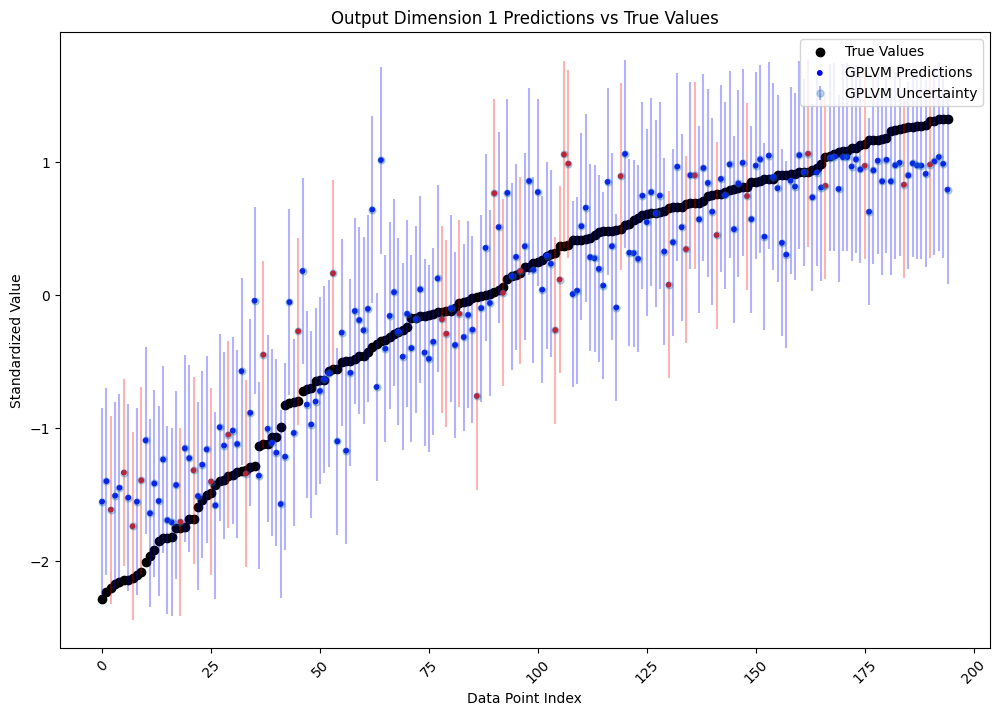

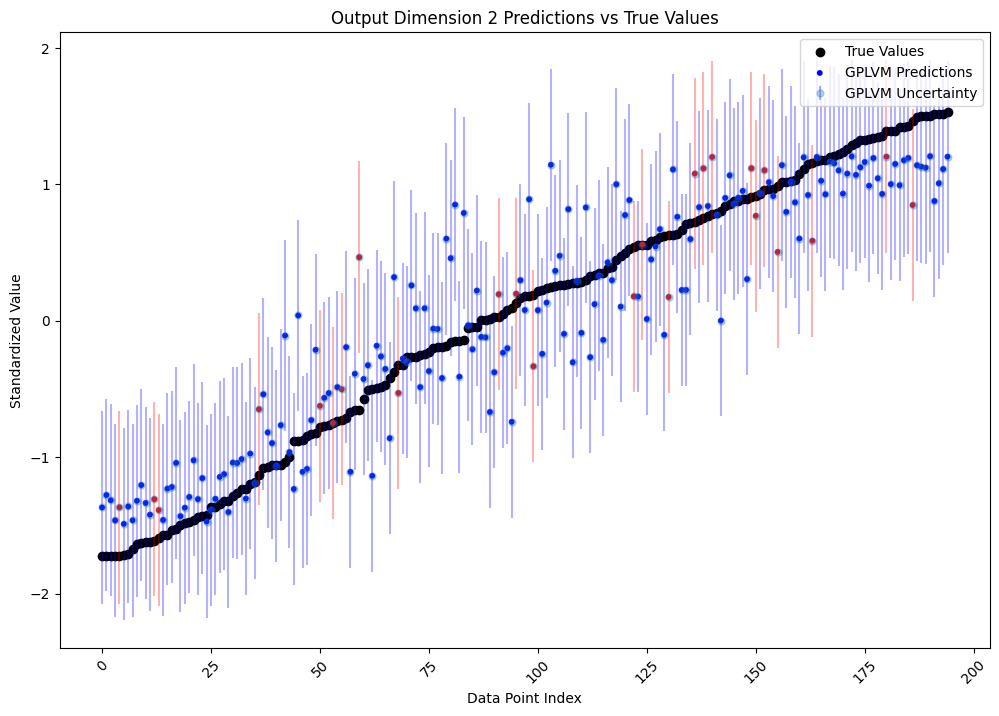

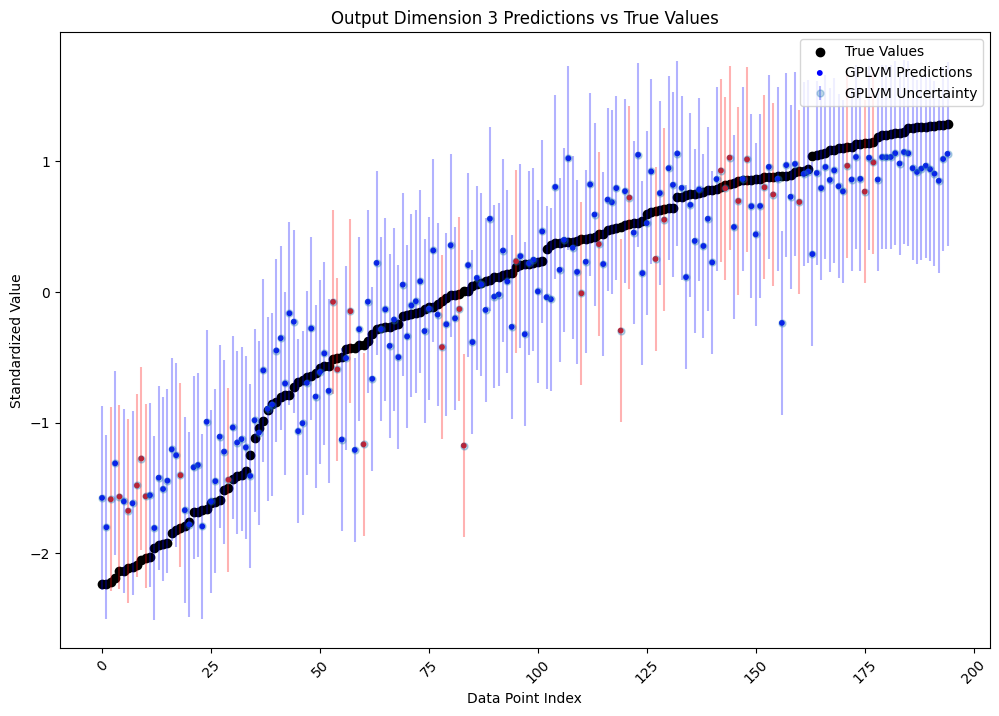

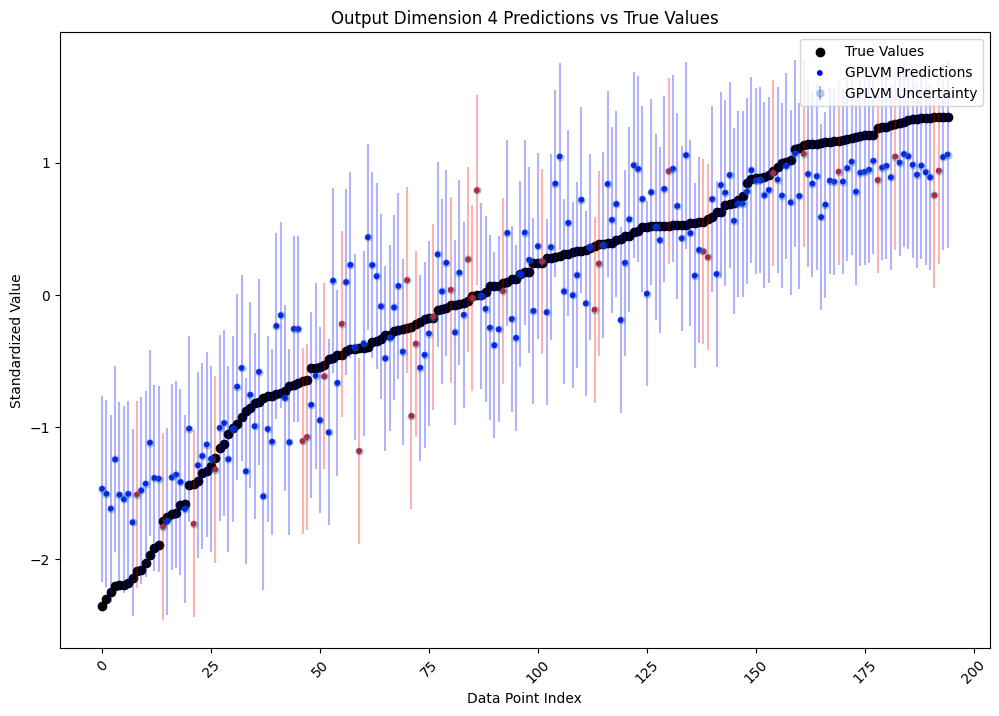

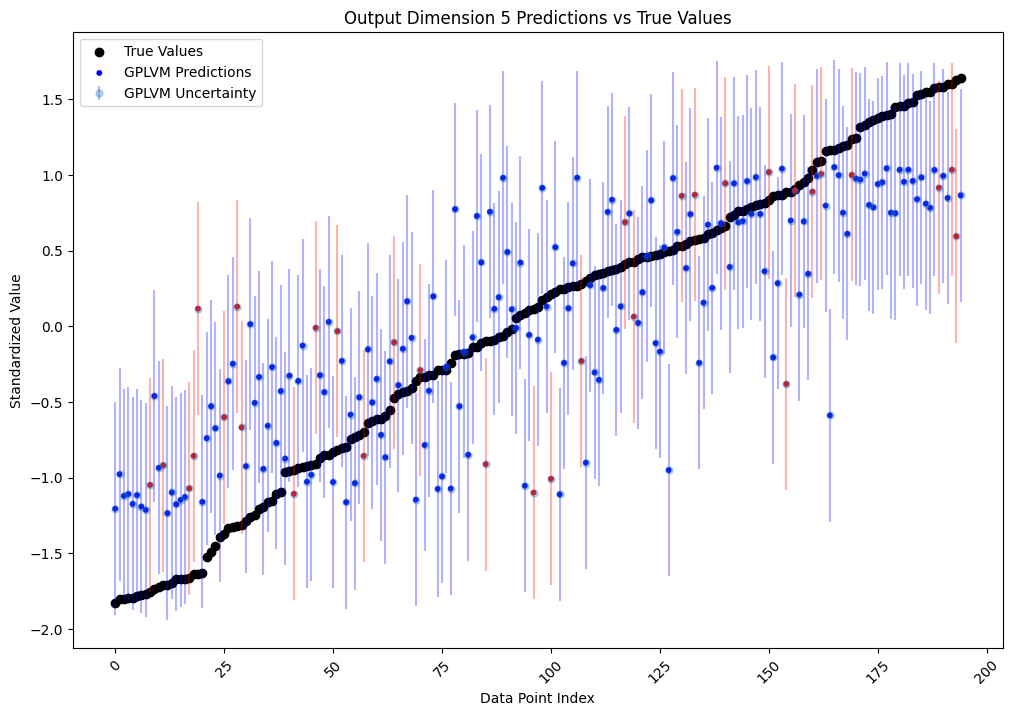

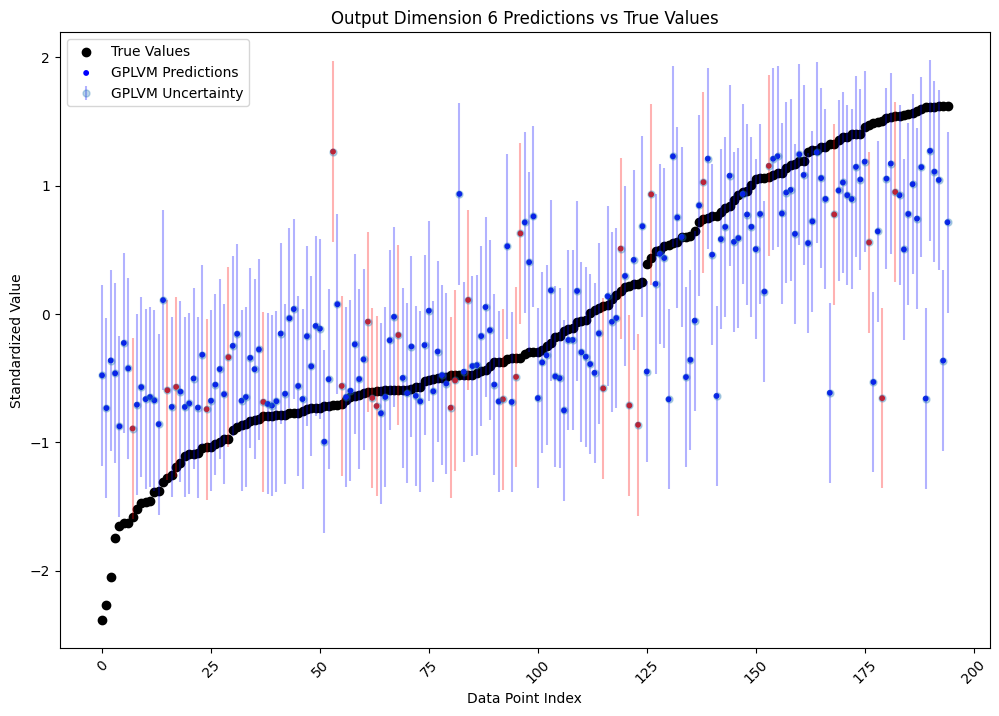

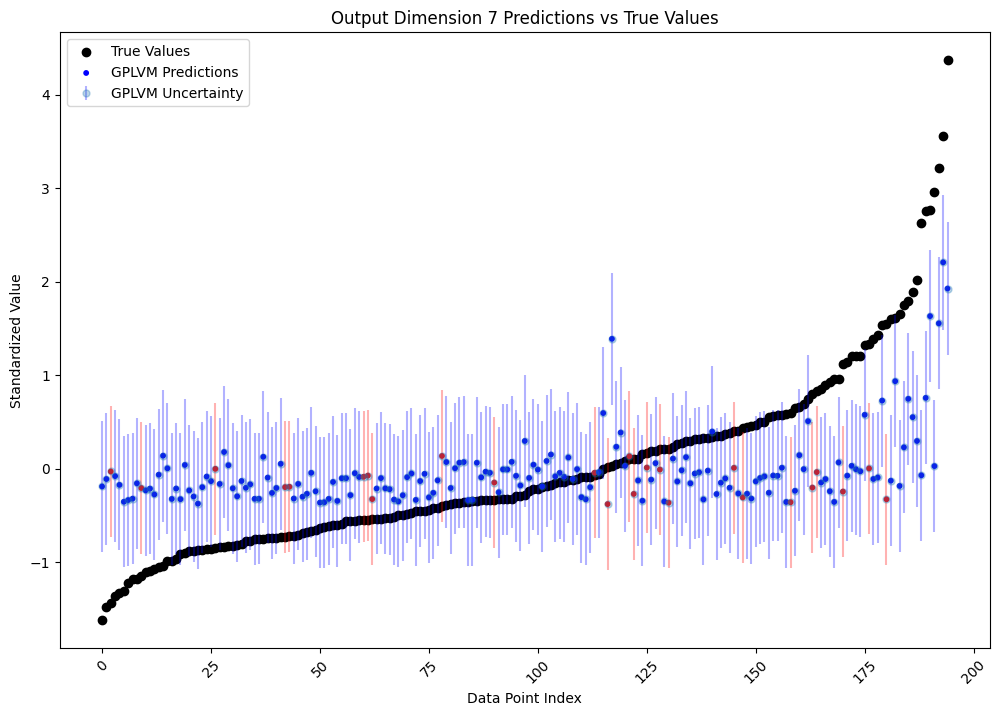

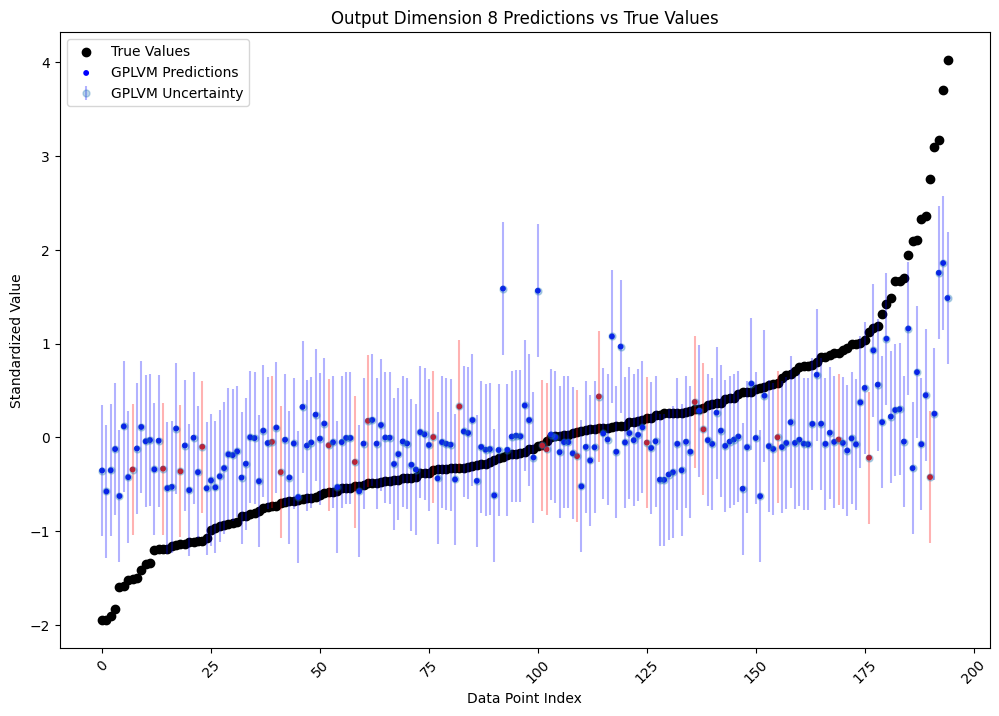

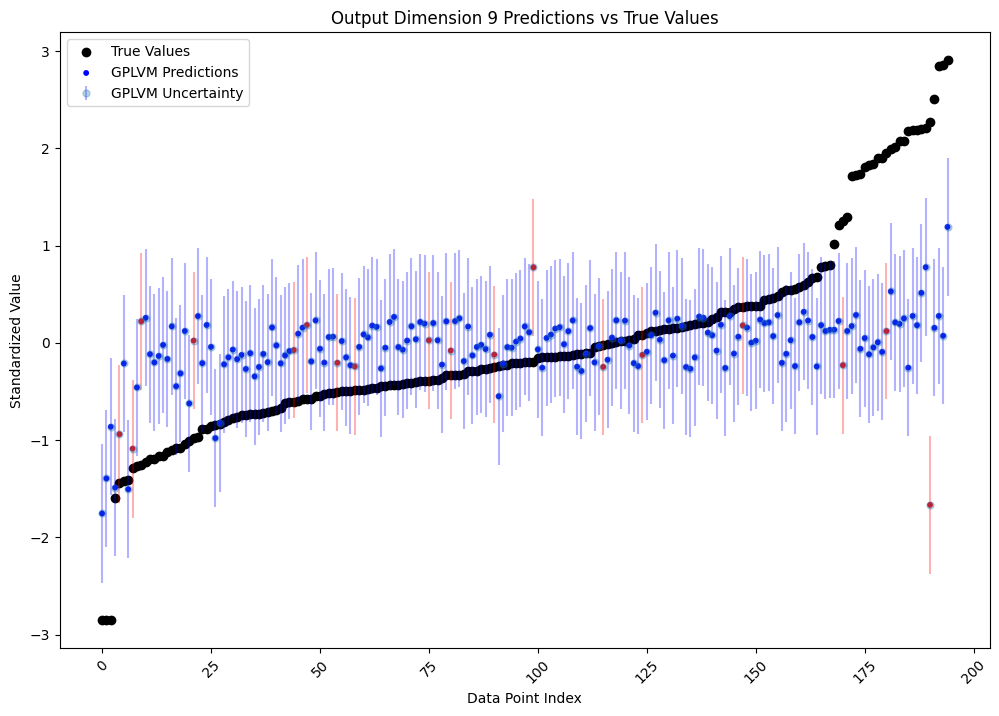

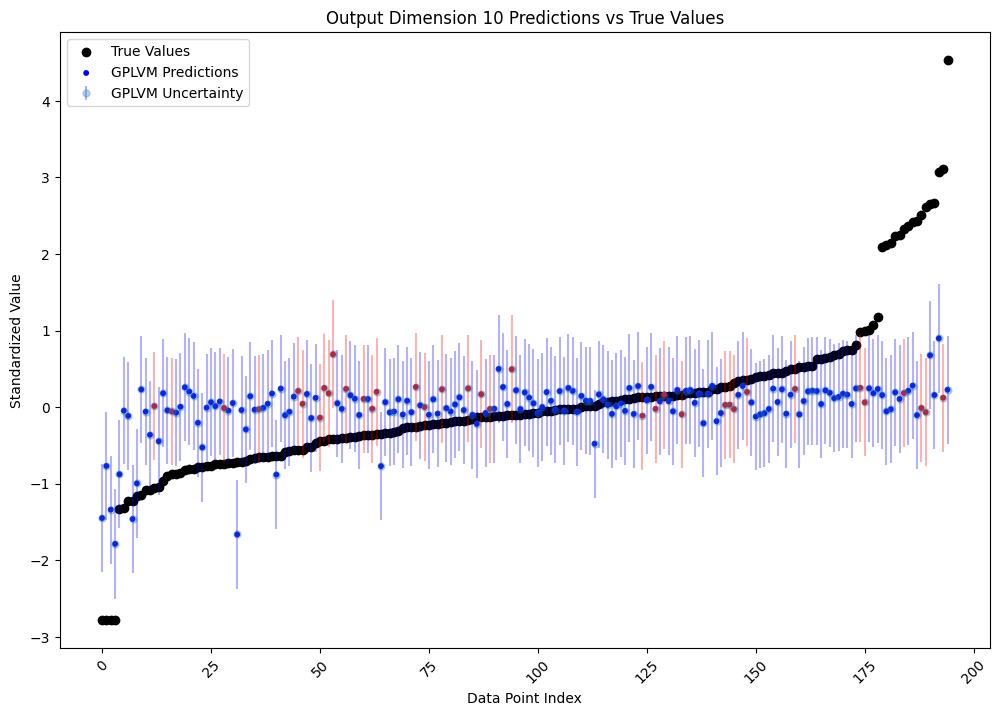

In [18]:
import matplotlib.pyplot as plt

data_norm_all = scaler.transform(all_data)

for j in range(data_norm_all.shape[1]):
    plt.figure(figsize=(12, 8))
    plt.title(f'Output Dimension {j+1} Predictions vs True Values')
    plt.xlabel('Data Point Index')
    plt.ylabel('Standardized Value')

    # Sort by true values for better visualization
    valid_indices = ~torch.isnan(data_norm_all[:, j])
    true_sorted, sorted_indices = torch.sort(data_norm_all[valid_indices, j])
    pred_sorted = f_means[valid_indices, j][sorted_indices]
    pred_std_sorted = torch.sqrt(f_vars[valid_indices, j][sorted_indices])
    # mean_sorted = data_norm_mean_masked[valid_indices, j][sorted_indices]
    # std_sorted = data_norm_std_masked[valid_indices, j][sorted_indices]

    # colour by mask 
    mask_sorted = missing_mask[valid_indices, j][sorted_indices]
    colors = ['red' if m else 'blue' for m in mask_sorted]
    cmap = plt.get_cmap('bwr')
    
    plt.scatter(np.arange(len(true_sorted)), true_sorted.numpy(), label='True Values', color='k')
    
    # Use the same color array for errorbar
    plt.errorbar(np.arange(len(pred_sorted)), pred_sorted.numpy(), yerr=pred_std_sorted.numpy(), 
                fmt='o', ecolor=colors, alpha=0.3, label='GPLVM Uncertainty', linestyle='None', markersize=5)
    plt.scatter(np.arange(len(pred_sorted)), pred_sorted.numpy(), label='GPLVM Predictions', color=colors, s=10)
    
   
    # plt.scatter(np.arange(len(mean_sorted)), mean_sorted.numpy(), label='Mean Predictor', color='green')
    # plt.errorbar(np.arange(len(mean_sorted)), mean_sorted.numpy(), yerr=std_sorted.numpy(), fmt='o', color='green', alpha=0.3, label='Mean Predictor Uncertainty', linestyle='None')
   
    
    plt.legend()
    plt.xticks(rotation=45)

## Plot the betas

/var/folders/kx/7zm2zp_54d14zbwnnl84lxlc0000gp/T/ipykernel_64896/1977586089.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')


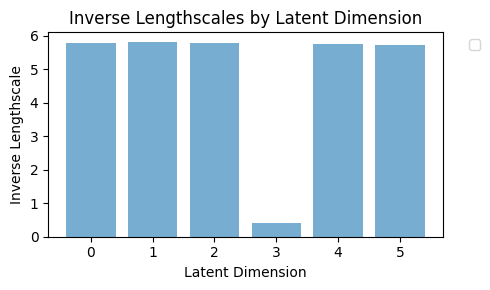

In [19]:
# plot the inverse lengthscales
import matplotlib.pyplot as plt

inverse_lengthscales = model.gp._log_beta.detach().cpu().numpy()
# inverse_lengthscales = 1.0 / lengthscales

plt.figure(figsize=(5, 3))

plt.bar(range(config.latent_dim), inverse_lengthscales[0], alpha=0.6)

plt.xlabel('Latent Dimension')
plt.ylabel('Inverse Lengthscale')
plt.title('Inverse Lengthscales by Latent Dimension')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [20]:
inverse_lengthscales

array([[5.78404246, 5.80547456, 5.76371874, 0.39671104, 5.75062245,
        5.71559617]])